In [2]:
import sys
project_root = "../.."
sys.path.append(project_root)

import seaborn as sns
import torch
from IPython.display import HTML
import matplotlib.pyplot as plt

# Import project packages
from src.simulation.visualization.animation import create_animation_1d
from src.simulation.equations.advdiff1d import AdvectionDiffusionEquation1D 

device = torch.device("cpu")
sns.set_style("ticks")
sns.set_context("paper")

In [3]:
eq = AdvectionDiffusionEquation1D(
    L=1.0,
    T=1.0,
    n_x=100,
    n_t=100,
    velocity={"type": "constant", "value": 0.3},
    diffusivity={"type": "constant", "value": 0.003},
    ic= {"type": "grf", "ell": 0.03, "normalize": True, "placeholder": 4, "seed": 53}, 
    bc={"type": "Periodic"},
    CFL=0.5,
    second_order=True,
)

snapshots = eq.solve()

frames = [[snapshots[i] for i in range(len(snapshots))]]
labels = ["Ground truth"]
animation = create_animation_1d(frames, labels, y_lim_min=-1, y_lim_max=1, fig_size_x=8, fig_size_y=4)
HTML(animation.to_html5_video())

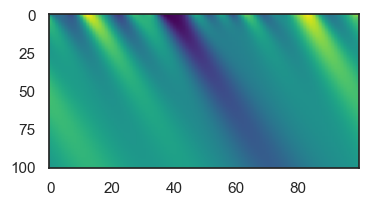

In [4]:
fig, ax = plt.subplots(figsize=(4, 2))
ax.imshow(snapshots, cmap="viridis", aspect="auto")

plt.show()